<a href="https://colab.research.google.com/github/leovarconrenno/Estacao-de-Reabastecimento-de-Hidrogenio---SCADA-Core/blob/main/etapa-03-arvores/Aula%2024%20-%20%C3%81rvore%20de%20Atingibilidade%20e%20Cobertura%20em%20Redes%20de%20Petri%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 24 - Notebook: Árvore de Atingibilidade e Cobertura (Karp-Miller) na HRS

Este notebook modela o subsistema `SUP-100` $\to$ `TK-103` $\to$ `HEX-201` $\to$ `DISP-300` + `ESD-100` por meio de **Redes de Petri**, detecta acúmulo ilimitado ($\omega$) com o algoritmo de **Karp-Miller** e aplica **síntese de controle por lugar complementar**.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
OMEGA = float("inf")

def fmt(m):
    return "(" + ",".join("w" if x == OMEGA else str(int(x)) for x in m) + ")"

class RedeDePetri:
    def __init__(self, lugares, transicoes, pre, post, m0):
        self.lugares = lugares
        self.transicoes = transicoes
        self.pre = np.array(pre, dtype=float)
        self.post = np.array(post, dtype=float)
        self.m0 = tuple(float(x) for x in m0)

    def habilitada(self, m, j):
        return all(m[i] >= self.pre[i, j] for i in range(len(self.lugares)))

    def disparar(self, m, j):
        return tuple(OMEGA if m[i] == OMEGA else m[i] - self.pre[i, j] + self.post[i, j] for i in range(len(self.lugares)))

def karp_miller(rdp: RedeDePetri, max_nos: int = 200):
    G = nx.DiGraph()
    G.add_node(rdp.m0)
    fila = [(rdp.m0, [rdp.m0])]
    visitados = {rdp.m0}
    while fila and len(G.nodes) < max_nos:
        m_atual, anc_lista = fila.pop(0)
        for j, t_nome in enumerate(rdp.transicoes):
            if rdp.habilitada(m_atual, j):
                m_prox = list(rdp.disparar(m_atual, j))
                for anc in anc_lista:
                    if all(m_prox[i] >= anc[i] for i in range(len(m_prox))) and tuple(m_prox) != anc:
                        for i in range(len(m_prox)):
                            if m_prox[i] > anc[i]:
                                m_prox[i] = OMEGA
                m_t = tuple(m_prox)
                if m_t not in G:
                    G.add_node(m_t)
                G.add_edge(m_atual, m_t, label=t_nome)
                if m_t not in visitados:
                    visitados.add(m_t)
                    fila.append((m_t, anc_lista + [m_t]))
    return G

In [2]:
# Cenario A: Sem controle de capacidade no buffer de DISP-300
lug_A = ["P1_SUP100", "P2_TK103_ADM", "P3_HEX201", "P4_BUFFER_DISP", "P5_ESD100"]
trans_A = ["T1_XV103", "T2_HEX201", "T3_LOTE_OK", "T4_TRIP_SIS", "T5_PURGA_N2_RESET"]
pre_A = [[1,0,0,0,0],[0,1,0,0,0],[0,0,1,1,0],[0,0,0,0,0],[0,0,0,0,1]]
post_A = [[0,0,1,0,1],[1,0,0,0,0],[0,1,0,0,0],[0,0,1,0,0],[0,0,0,1,0]]
rdp_A = RedeDePetri(lug_A, trans_A, pre_A, post_A, [1, 0, 0, 0, 0])
G_A = karp_miller(rdp_A)

print("=== Transições Cenário A (Detecção de w em P4_BUFFER_DISP) ===")
for u, v, d in G_A.edges(data=True):
    print(f"  {fmt(u)} --[{d['label']}]--> {fmt(v)}")

# Cenario B: Lugar complementar P6_ESPACO_LIVRE (K_max = 2) + T6_DISPENSAR
lug_B = lug_A + ["P6_ESPACO_LIVRE"]
trans_B = trans_A + ["T6_DISPENSAR_FCEV"]
pre_B = [[1,0,0,0,0,0],[0,1,0,0,0,0],[0,0,1,1,0,0],[0,0,0,0,0,1],[0,0,0,0,1,0],[0,0,1,0,0,0]]
post_B = [[0,0,1,0,1,0],[1,0,0,0,0,0],[0,1,0,0,0,0],[0,0,1,0,0,0],[0,0,0,1,0,0],[0,0,0,0,0,1]]
rdp_B = RedeDePetri(lug_B, trans_B, pre_B, post_B, [1, 0, 0, 0, 0, 2])
G_B = karp_miller(rdp_B)

def auditar(G, nome):
    estados = list(G.nodes)
    ilimitada = any(OMEGA in e for e in estados)
    deadlocks = [fmt(e) for e in estados if G.out_degree(e) == 0]
    exclusao = not any(e[2] > 0 and e[4] > 0 for e in estados)
    print(f"[{nome}] Estados={len(estados)} | Limitada={not ilimitada} | Deadlocks={len(deadlocks)} | Exclusão Mútua HEX201/ESD100={exclusao}")

print()
auditar(G_A, "Cenário A - Sem Controle")
auditar(G_B, "Cenário B - Lugar Complementar K=2")

=== Transições Cenário A (Detecção de w em P4_BUFFER_DISP) ===
  (1,0,0,0,0) --[T1_XV103]--> (0,1,0,0,0)
  (0,1,0,0,0) --[T2_HEX201]--> (0,0,1,0,0)
  (0,0,1,0,0) --[T3_LOTE_OK]--> (1,0,0,w,0)
  (0,0,1,0,0) --[T4_TRIP_SIS]--> (0,0,0,0,1)
  (1,0,0,w,0) --[T1_XV103]--> (0,1,0,w,0)
  (0,0,0,0,1) --[T5_PURGA_N2_RESET]--> (1,0,0,0,0)
  (0,1,0,w,0) --[T2_HEX201]--> (0,0,1,w,0)
  (0,0,1,w,0) --[T3_LOTE_OK]--> (1,0,0,w,0)
  (0,0,1,w,0) --[T4_TRIP_SIS]--> (0,0,0,w,1)
  (0,0,0,w,1) --[T5_PURGA_N2_RESET]--> (1,0,0,w,0)

[Cenário A - Sem Controle] Estados=8 | Limitada=False | Deadlocks=0 | Exclusão Mútua HEX201/ESD100=True
[Cenário B - Lugar Complementar K=2] Estados=12 | Limitada=True | Deadlocks=0 | Exclusão Mútua HEX201/ESD100=True


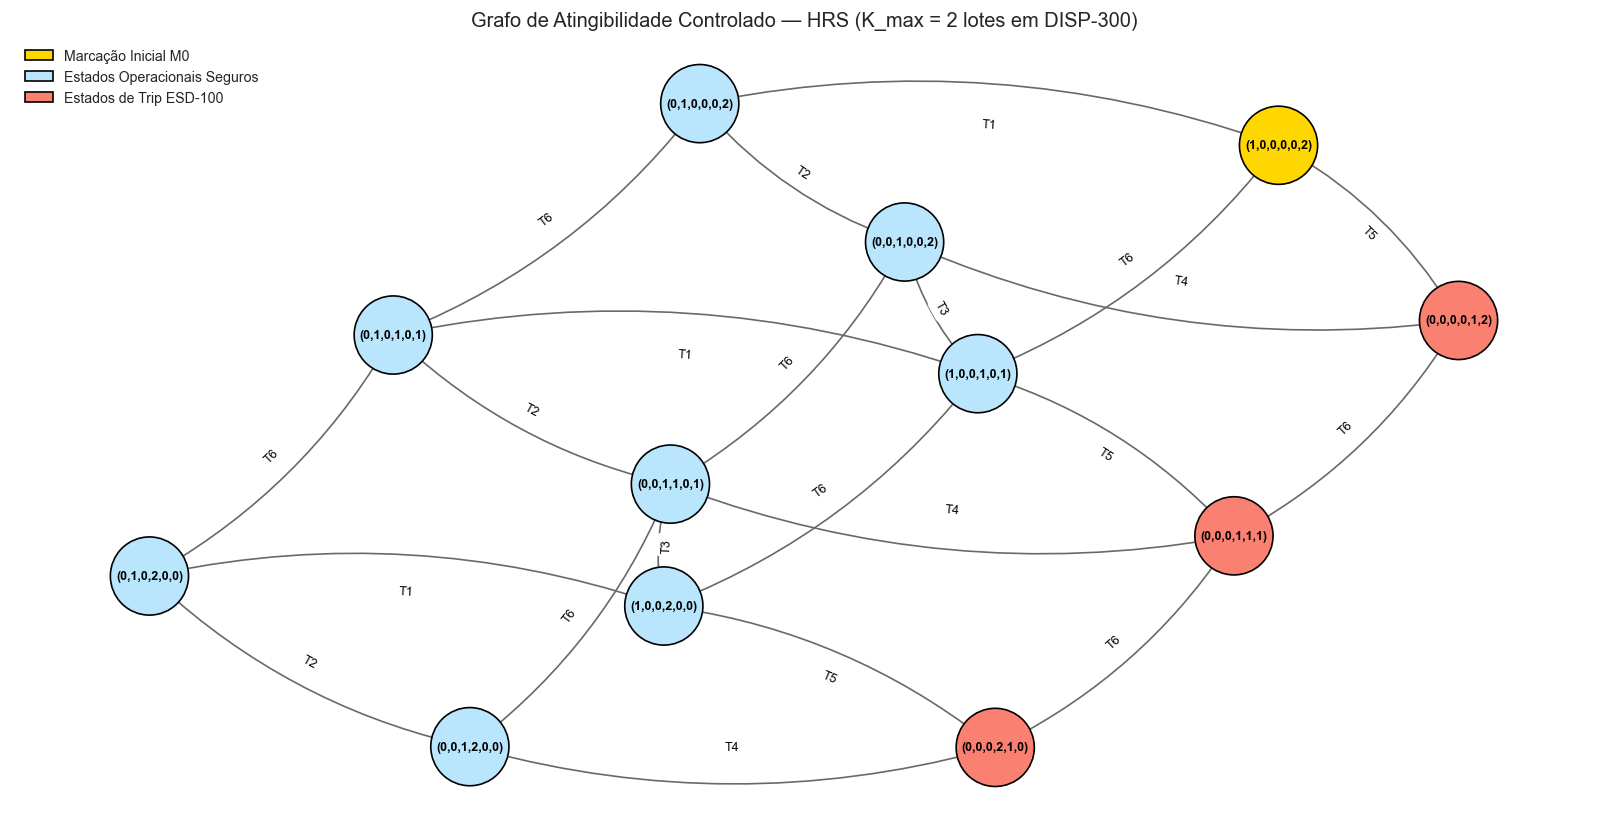

In [3]:
fig, ax = plt.subplots(figsize=(13.5, 7.0))
pos = nx.kamada_kawai_layout(G_B)
cores = ["gold" if n == rdp_B.m0 else ("salmon" if n[4] > 0 else "#bae6fd") for n in G_B.nodes]
nx.draw_networkx_nodes(G_B, pos, ax=ax, node_color=cores, node_size=2200, edgecolors="black")
nx.draw_networkx_labels(G_B, pos, labels={n: fmt(n) for n in G_B.nodes}, ax=ax, font_size=7.5, font_weight="bold")
nx.draw_networkx_edges(G_B, pos, ax=ax, edge_color="dimgray", arrows=True, arrowsize=14, connectionstyle="arc3,rad=0.14")
edge_labels = {(u, v): d["label"].split("_")[0] for u, v, d in G_B.edges(data=True)}
nx.draw_networkx_edge_labels(G_B, pos, edge_labels=edge_labels, ax=ax, font_size=7.5)
legenda = [
    Patch(facecolor="gold", edgecolor="black", label="Marcação Inicial M0"),
    Patch(facecolor="#bae6fd", edgecolor="black", label="Estados Operacionais Seguros"),
    Patch(facecolor="salmon", edgecolor="black", label="Estados de Trip ESD-100"),
]
ax.legend(handles=legenda, loc="upper left", fontsize=8.5)
ax.set_title("Grafo de Atingibilidade Controlado — HRS (K_max = 2 lotes em DISP-300)", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.show()